<h1 id="exercise-1"><strong>Exercise 1</strong></h1>

In [1]:
import csv
import numpy as np
from typing import Set,Tuple, List
import torch
import torch.utils
import torch.utils.data
import torch.nn as nn
import torchvision
NoneType = type(None)
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
from PIL import Image
import torchvision.transforms.functional as TF
from torchvision.models import vgg11
from torchvision.models import mobilenet_v2
import torchvision.transforms as transforms
import time


In [ ]:
# wrong part: def id_to_fruit(fruit_id: int, fruits: Set[str]) -> str:

def id_to_fruit(fruit_id: int, fruits: list[str]) -> str:
    """
    This method returns the fruit name by getting the string at a specific index of the set.

    :param fruit_id: The id of the fruit to get
    :param fruits: The set of fruits to choose the id from
    :return: The string corrosponding to the index ``fruit_id``

    **This method is part of a series of debugging exercises.**
    **Each Python method of this series contains bug that needs to be found.**

    | ``1   It does not print the fruit at the correct index, why is the returned result wrong?``
    | ``2   How could this be fixed?``

    This example demonstrates the issue:
    name1, name3 and name4 are expected to correspond to the strings at the indices 1, 3, and 4:
    'orange', 'kiwi' and 'strawberry'..

    >>> name1 = id_to_fruit(1, {"apple", "orange", "melon", "kiwi", "strawberry"})
    >>> name3 = id_to_fruit(3, {"apple", "orange", "melon", "kiwi", "strawberry"})
    >>> name4 = id_to_fruit(4, {"apple", "orange", "melon", "kiwi", "strawberry"})
    """
    idx = 0
    for fruit in fruits:
        if fruit_id == idx:
            return fruit
        idx += 1
    raise RuntimeError(f"Fruit with id {fruit_id} does not exist")



In [ ]:
# Wrong Code:

# name1 = id_to_fruit(1, {"apple", "orange", "melon", "kiwi", "strawberry"})
# name3 = id_to_fruit(3, {"apple", "orange", "melon", "kiwi", "strawberry"})
# name4 = id_to_fruit(4, {"apple", "orange", "melon", "kiwi", "strawberry"})
# print(name1, name3, name4)

# Edited Code:
fruits = ["apple", "orange", "melon", "kiwi", "strawberry"]
name1 = id_to_fruit(1, fruits)
name3 = id_to_fruit(3, fruits)
name4 = id_to_fruit(4, fruits)
print("Response After Edit:", name1, name3, name4)


strawberry kiwi apple
Response after Edit: orange kiwi strawberry


<h1 id="exercise-2"><strong>Exercise 2</strong></h1>


<font size="4px">
<span style="color:#008B8B">
<br /><strong style="color: #D35400;">Answer: </strong> On the right-hand side, coords[:, 1] appears twice. The second item should be coords[:, 0].
 <br /><br /><br /><hr style="border: none; height: 2px; background-color: #7c57e0; width: 80%; margin: 0px 0px;"><br />

<code>2   After fixing the obvious error it is still wrong, how can this be fixed?</code></div>
<br /><span style="color:#008B8B;"><strong style="color: #D35400;">Answer: </strong>In numpy, slicing like coords[:, 0] creates a view, not a copy. This means both columns can share the same data, so changing one column may also affect the other. As a result, the initial values of columns 0 and 2 are lost.
 <br /><br /><br /><hr style="border: none; height: 2px; background-color: #7c57e0; width: 80%; margin: 0px 0px;"><br />
<br /><strong style="color: #1f8825;">Fix: </strong> Use fancy indexing to swap the columns safely, since it creates a copy. Also, make a copy of the input array first to avoid changing the original data. 
<br /><span  style="color: #f83d3d;"> def swap(coords: np.ndarray): </span> <strong style="margin-left: 40px; margin-right: 40px; color: #7c57e0; font-size: 22px;">&rArr;</strong> def swap(coords: np.ndarray) <span  style="color: #1f8825;"> -> np.ndarray: </span>
<br /><br /><br /><hr style="border: none; height: 2px; background-color: #7c57e0; width: 80%; margin: 0px 0px;"><br />
<br /><span  style="color: #f83d3d;"> coords[:, 0], coords[:, 1], coords[:, 2], coords[:, 3], = coords[:, 1], coords[:, 1], coords[:, 3], coords[:, 2] <br /> return coords</span>
<br /><strong style="margin-left: 40px; margin-right: 40px; color: #7c57e0; font-size: 22px;">&rArr;</strong>
<br /><span  style="color: #1f8825;">swapped = coords.copy()<br />swapped[:, [0, 1, 2, 3]] = coords[:, [1, 0, 3, 2]]<br />return swapped </span></p><br />
</div><br />


</font>

In [4]:
# You can copy this code to your personal pipeline project or execute it here.
# Wrong code: def swap(coords: np.ndarray):
def swap(coords: np.ndarray) -> np.ndarray:
    """
    This method will flip the x and y coordinates in the coords array.

    :param coords: A numpy array of bounding box coordinates with shape [n,5] in format:
        ::

            [[x11, y11, x12, y12, classid1],
             [x21, y21, x22, y22, classid2],
             ...
             [xn1, yn1, xn2, yn2, classid3]]

    :return: The new numpy array where the x and y coordinates are flipped.

    **This method is part of a series of debugging exercises.**
    **Each Python method of this series contains bug that needs to be found.**

    | ``1   Can you spot the obvious error?``
    | ``2   After fixing the obvious error it is still wrong, how can this be fixed?``

    >>> import numpy as np
    >>> coords = np.array([[10, 5, 15, 6, 0],
    ...                    [11, 3, 13, 6, 0],
    ...                    [5, 3, 13, 6, 1],
    ...                    [4, 4, 13, 6, 1],
    ...                    [6, 5, 13, 16, 1]])
    >>> swapped_coords = swap(coords)

    The example demonstrates the issue. The returned swapped_coords are expected to have swapped
    x and y coordinates in each of the rows.
    """
    # Wrong code:
    # coords[:, 0], coords[:, 1], coords[:, 2], coords[:, 3], = coords[:, 1], coords[:, 1], coords[:, 3], coords[:, 2]
    # return coords
    
    # Corrected code:
    swapped = coords.copy()                              # don't modify the input
    swapped[:, [0, 1, 2, 3]] = coords[:, [1, 0, 3, 2]]   # fancy indexing creates a copy
    return swapped



In [5]:
import numpy as np
coords = np.array([[10, 5, 15, 6, 0],
                   [11, 3, 13, 6, 0],
                   [5, 3, 13, 6, 1],
                   [4, 4, 13, 6, 1],
                   [6, 5, 13, 16, 1]])
swapped_coords = swap(coords)
print(swapped_coords)


[[ 5 10  6 15  0]
 [ 3 11  6 13  0]
 [ 3  5  6 13  1]
 [ 4  4  6 13  1]
 [ 5  6 16 13  1]]


<h1 id="exercise-3"><strong>Exercise 3</strong></h1>


<font size="4px">
<div class="line-block"><code>1   For some reason the plot is not showing correctly, can you find out what is going wrong?</code><br />
<div style="color:#008B8B">
<strong style="color: #D35400;">Answer: </strong> csv.reader returns every value as a string. np.stack turns these strings into an array of strings, not floats. Matplotlib treats string values as categories, not numbers: it places them at positions 0, 1, 2, … in the order they appear, instead of at their numeric values. With the axis limits set to -0.05–1.05, only the first two points are visible, and the plot is a single straight line. 
</div><br />
<code>2   How could this be fixed?</code></div>
<div style="color:#008B8B">
<strong style="color: #D35400;">Answer: </strong> Convert each value to float while reading the file.
<br /><br />The docstring says precision should be on the x-axis and recall on the y-axis, but the code plots recall on x. The axis labels were swapped too, so they matched the data. This is a mismatch with the docstring, not a wrong plot. The fix below follows the docstring. (The common convention for PR curves is the opposite, recall on x. Either is fine as long as the data and the labels match.)
<br /><br />On Windows, a CSV file opened without newline="" gets an extra \r at the end of each line. csv.reader then returns an empty row [] after every data row, and np.stack fails. The CSV module docs say to open CSV files with newline="". <br />
<br />
<br /><span style="color:#008B8B;"><strong style="color: #1f8825;">Fix: </strong> ... 
<br /><p><span  style="color: #f83d3d;"> with open(csv_file_path) as result_csv:</span>  <strong style="margin-left: 40px; margin-right: 40px; color: #7c57e0; font-size: 22px;">&rArr;</strong>
<span  style="color: #D35400 ;"> with open(csv_file_path<span style="color: #1f8825;">, newline=""</span>) as result_csv:</span></p>
<br /><br /><br /><hr style="border: none; height: 2px; background-color: #7c57e0; width: 80%; margin: 0px 0px;"><br />
<br /><br /><span  style="color: #f83d3d;margin-left: 80px;">results.append(row)</span>
<br /><span  style="color: #f83d3d;margin-left: 40px;">results = np.stack(results) </span>
<strong style="margin-left: 40px; margin-right: 40px; color: #7c57e0; font-size: 22px;">&rArr;</strong>
<span  style="color: #1f8825;">
<br /><span style="margin-left: 80px;">if not row:</span>
<br /><span style="margin-left: 120px;">continue</span>
<br /><span style="margin-left: 80px;">results.append([float(v) for v in row])</span>
<br /><span style="margin-left: 0px;">results = np.stack(results)</span>
<br /><br /><br /><hr style="border: none; height: 2px; background-color: #7c57e0; width: 80%; margin: 0px 0px;"><br />

<br /><p><span  style="color: #f83d3d;"> plt.plot(results[:, 1], results[:, 0])</span><strong style="margin-left: 40px; margin-right: 40px; color: #7c57e0; font-size: 22px;">&rArr;</strong><span  style="color: #D35400;"> plt.plot(results[:, <span  style="color:  #1f8825;">0</span>], results[:, <span  style="color: #1f8825;">1</span>])</span></p>
<br /><br /><br /><hr style="border: none; height: 2px; background-color: #7c57e0; width: 80%; margin: 0px 0px;"><br />

<br /><br /><span  style="color: #f83d3d;">plt.xlabel('Recall') <br />  plt.xlabel('Precision') </span><strong style="margin-left: 40px; margin-right: 40px; color: #7c57e0; font-size: 22px;">&rArr;</strong>
<br /> <span  style="color: #1f8825">plt.xlabel('Precision')  <br />  plt.xlabel('Recall')  </span> 
<br /><div>
<br /><br /><br /><hr style="border: none; height: 2px; background-color: #7c57e0; width: 80%; margin: 0px 0px;"><br />

<br /><p><span  style="color: #f83d3d;"> f = open("data_file.csv", "w")  </span><strong style="margin-left: 40px; margin-right: 40px; color: #7c57e0; font-size: 22px;">&rArr;</strong><span  style="color: #D35400 ;"> f = open("data_file.csv", "w"<span  style="color: #1f8825;"> , newline="" </span>) </span></p>
</div></div>
</font>

In [ ]:
def plot_data(csv_file_path: str):
    """
    This code plots the precision-recall curve based on data from a .csv file,
    where precision is on the x-axis and recall is on the y-axis.
    It it not so important right now what precision and recall means.

    :param csv_file_path: The CSV file containing the data to plot.


    **This method is part of a series of debugging exercises.**
    **Each Python method of this series contains bug that needs to be found.**

    | ``1   For some reason the plot is not showing correctly, can you find out what is going wrong?``
    | ``2   How could this be fixed?``

    This example demonstrates the issue.
    It first generates some data in a csv file format and the plots it using the ``plot_data`` method.
    If you manually check the coordinates and then check the plot, they do not correspond.

    >>> f = open("data_file.csv", "w")
    >>> w = csv.writer(f)
    >>> _ = w.writerow(["precision", "recall"])
    >>> w.writerows([[0.013,0.951],
    ...              [0.376,0.851],
    ...              [0.441,0.839],
    ...              [0.570,0.758],
    ...              [0.635,0.674],
    ...              [0.721,0.604],
    ...              [0.837,0.531],
    ...              [0.860,0.453],
    ...              [0.962,0.348],
    ...              [0.982,0.273],
    ...              [1.0,0.0]])
    >>> f.close()
    >>> plot_data('data_file.csv')
    """
    # load data
    results = []
    # print(open("data_file.csv", "rb").read()[:40])
    # Wrong code: with open(csv_file_path) as result_csv:
    with open("data_file.csv", newline="") as result_csv:
        csv_reader = csv.reader(result_csv, delimiter=',')
        header = next(csv_reader)
        print(header)  
        for row in csv_reader:
            # Wrong code: results.append(row)
            if not row:
                continue
            results.append([float(v) for v in row])
        results = np.stack(results)
        print("results after np.stack:\n",results)


    # plot precision-recall curve
    plt.plot(results[:, 1], results[:, 0])
    plt.ylim([-0.05, 1.05])
    plt.xlim([-0.05, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.show()



['precision', 'recall']
results after np.stack:
 [[0.013 0.951]
 [0.376 0.851]
 [0.441 0.839]
 [0.57  0.758]
 [0.635 0.674]
 [0.721 0.604]
 [0.837 0.531]
 [0.86  0.453]
 [0.962 0.348]
 [0.982 0.273]
 [1.    0.   ]]


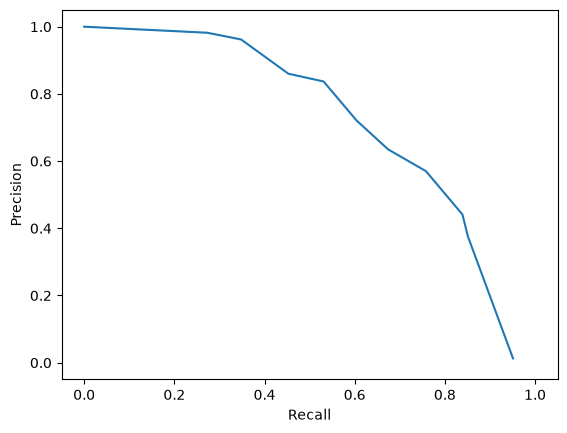

In [7]:
#Wrong code:  f = open("data_file.csv", "w")
f = open("data_file.csv", "w", newline="")
w = csv.writer(f)
_ = w.writerow(["precision", "recall"])
w.writerows([[0.013,0.951],
             [0.376,0.851],
             [0.441,0.839],
             [0.570,0.758],
             [0.635,0.674],
             [0.721,0.604],
             [0.837,0.531],
             [0.860,0.453],
             [0.962,0.348],
             [0.982,0.273],
             [1.0,0.0]])
f.close()
plot_data('data_file.csv')


<h1 id="generator-for-exercise-4"><Strong>Generator (for Exercise 4)</string></h1>


<font size="4px"><p>Generator class for the GAN</p>
</font>

In [8]:
# You can copy this code to your personal pipeline project or execute it here.
class Generator(nn.Module):
    """
    Generator class for the GAN
    """

    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(100, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 1024),
            nn.ReLU(),
            nn.Linear(1024, 784),
            nn.Tanh(),
        )

    def forward(self, x):
        output = self.model(x)
        output = output.view(x.size(0), 1, 28, 28)
        return output



<h1 id="discriminator-for-exercise-4"><strong>Discriminator (for Exercise 4)</strong></h1>


<font size="4px"><p>Discriminator class for the GAN</p>
</font>

In [9]:
# You can copy this code to your personal pipeline project or execute it here.
class Discriminator(nn.Module):
    """
    Discriminator class for the GAN
    """
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(784, 1024),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        x = x.view(x.size(0), 784)
        output = self.model(x)
        return output



<h1 id="exercise-4"><strong>Exercise 4</strong></h1>


In [ ]:
def train_gan(batch_size: int = 32, num_epochs: int = 100, device: str = "cuda:0" if torch.cuda.is_available() else "cpu"):
    transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])

    try:
        train_set = torchvision.datasets.MNIST(root=".", train=True, download=True, transform=transform)
    except:
        print("Failed to download MNIST, retrying with different URL")
        # see: https://github.com/pytorch/vision/blob/master/torchvision/datasets/mnist.py
        torchvision.datasets.MNIST.resources = [
            ('https://ossci-datasets.s3.amazonaws.com/mnist/train-images-idx3-ubyte.gz',
             'f68b3c2dcbeaaa9fbdd348bbdeb94873'),
            ('https://ossci-datasets.s3.amazonaws.com/mnist/train-labels-idx1-ubyte.gz',
             'd53e105ee54ea40749a09fcbcd1e9432'),
            ('https://ossci-datasets.s3.amazonaws.com/mnist/t10k-images-idx3-ubyte.gz',
             '9fb629c4189551a2d022fa330f9573f3'),
            ('https://ossci-datasets.s3.amazonaws.com/mnist/t10k-labels-idx1-ubyte.gz',
             'ec29112dd5afa0611ce80d1b7f02629c')
        ]
        train_set = torchvision.datasets.MNIST(root=".", train=True, download=True, transform=transform)

    train_loader = torch.utils.data.DataLoader(train_set, batch_size=batch_size, shuffle=True)

    # example data
    real_samples, mnist_labels = next(iter(train_loader))

    fig = plt.figure()
    for i in range(16):
        sub = fig.add_subplot(4, 4, 1 + i)
        sub.imshow(real_samples[i].reshape(28, 28), cmap="gray_r")
        sub.axis('off')

    fig.tight_layout()
    fig.suptitle("Real images")
    display(fig)
    plt.close(fig)          # FIX: release the figure so it is not displayed twice

    time.sleep(5)

    # Set up training
    discriminator = Discriminator().to(device)
    generator = Generator().to(device)
    lr = 0.0001
    loss_function = nn.BCELoss()
    optimizer_discriminator = torch.optim.Adam(discriminator.parameters(), lr=lr)
    optimizer_generator = torch.optim.Adam(generator.parameters(), lr=lr)

    # train
    for epoch in range(num_epochs):
        for n, (real_samples, mnist_labels) in enumerate(train_loader):
            # FIX (structural bug): the last batch of an epoch can be smaller than
            # batch_size (60000 % 64 = 32), so use the real size of the current batch.
            current_batch_size = real_samples.size(0)
            
            # Data for training the discriminator
            real_samples = real_samples.to(device=device)
            # real_samples_labels = torch.ones((batch_size, 1)).to(device=device)
            real_samples_labels = torch.ones((current_batch_size, 1)).to(device=device)

            # latent_space_samples = torch.randn((batch_size, 100)).to(device=device)
            latent_space_samples = torch.randn((current_batch_size, 100)).to(device=device)
            
            generated_samples = generator(latent_space_samples)
            # generated_samples_labels = torch.zeros((batch_size, 1)).to(device=device)
            generated_samples_labels = torch.zeros((current_batch_size, 1)).to(device=device)
            
            all_samples = torch.cat((real_samples, generated_samples))
            all_samples_labels = torch.cat((real_samples_labels, generated_samples_labels))

            # Training the discriminator
            discriminator.zero_grad()
            output_discriminator = discriminator(all_samples)
            loss_discriminator = loss_function(output_discriminator, all_samples_labels)
            loss_discriminator.backward()
            optimizer_discriminator.step()

            # Data for training the generator
            # latent_space_samples = torch.randn((batch_size, 100)).to(device=device)
            latent_space_samples = torch.randn((current_batch_size, 100)).to(device=device)


            # Training the generator
            generator.zero_grad()
            generated_samples = generator(latent_space_samples)
            output_discriminator_generated = discriminator(generated_samples)
            loss_generator = loss_function(output_discriminator_generated, real_samples_labels)
            loss_generator.backward()
            optimizer_generator.step()

            # FIX (cosmetic bug): show loss and samples at the END of each epoch.
            # The original `n == batch_size - 1` compared a batch index with the batch size.
            
            # Show loss and samples generated
            # if n == batch_size - 1:
            if n == len(train_loader) - 1:
                name = f"Generate images\n Epoch: {epoch} Loss D.: {loss_discriminator:.2f} Loss G.: {loss_generator:.2f}"
                generated_samples = generated_samples.detach().cpu().numpy()
                fig = plt.figure()
                # for i in range(16):
                for i in range(min(16, len(generated_samples))):      # FIX: last batch may hold fewer than 16
                    sub = fig.add_subplot(4, 4, 1 + i)
                    sub.imshow(generated_samples[i].reshape(28, 28), cmap="gray_r")
                    sub.axis('off')
                fig.suptitle(name)
                fig.tight_layout()
                clear_output(wait=False)
                display(fig)
                plt.close(fig)          # FIX: release the figure



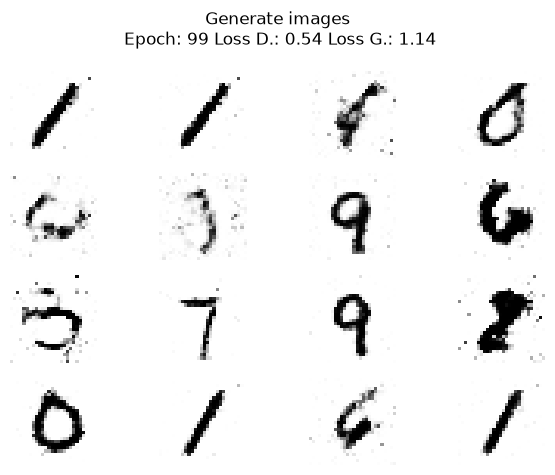

In [11]:
# train_gan(batch_size=32, num_epochs=100)
train_gan(batch_size=64, num_epochs=100)


<font size="4px">
<h1 id="exercise-4"><strong>Exercise 4 Answer:</strong></h1>

<code>1   Changing the batch_size from 32 to 64 triggers the structural bug.</code>
<br /><div style="color: #008B8B;"><strong style="color: #D35400;">Answer:
<br /></strong>The labels and the noise are always created with batch_size rows, but the last batch of each epoch can be smaller. MNIST has 60,000 training images:
<br />With batch_size=32: 60000 / 32 = 1875 full batches, so the bug stays hidden.
<br />With batch_size=64: 937 full batches plus a last batch of only 32 images.
<br />In that last batch, all_samples has 32 real + 64 generated = 96 rows, but all_samples_labels has 64 + 64 = 128 rows.
<br />BCELoss needs exactly one label per prediction, so it raises the size-mismatch error.</div>

<br /><br /><br /><hr style="border: none; height: 2px; background-color: #7c57e0; width: 80%; margin: 0px 0px;"><br />

<div style="color:#008B8B;"><strong style="color: #1f8825;">Fix: </strong>Use the actual size of the current batch, real_samples.size(0), for the labels and the noise.
<br />(Alternative: drop_last=True in the DataLoader, which skips the incomplete batch.)<br />

<p>for epoch in range(num_epochs):
<br /><span style="margin-left: 40px;">for n, (real_samples, mnist_labels) in enumerate(train_loader):</span></p>

<p style="margin-left: 80px;">
<span style="color: #1f8825;"># the last batch of an epoch can be smaller than batch_size
<br />current_batch_size = real_samples.size(0)</span>
<br />
<br /># Data for training the discriminator
<br />real_samples = real_samples.to(device=device)
<br /><span style="color: #f83d3d;">real_samples_labels = torch.ones((batch_size, 1)).to(device=device)</span><strong style="margin-left: 40px; margin-right: 40px; color: #7c57e0; font-size: 22px;">&rArr;</strong>real_samples_labels = torch.ones((<span style="color: #1f8825;">current_batch_size</span>, 1)).to(device=device)
<br /><span style="color: #f83d3d;">latent_space_samples = torch.randn((batch_size, 100)).to(device=device)</span><strong style="margin-left: 40px; margin-right: 40px; color: #7c57e0; font-size: 22px;">&rArr;</strong>latent_space_samples = torch.randn((<span style="color: #1f8825;">current_batch_size</span>, 100)).to(device=device)
<br /><span>generated_samples = generator(latent_space_samples)</span>
<br /><span style="color: #f83d3d;">generated_samples_labels = torch.zeros((batch_size, 1)).to(device=device)</span><strong style="margin-left: 40px; margin-right: 40px; color: #7c57e0; font-size: 22px;">&rArr;</strong>generated_samples_labels = torch.zeros((<span style="color: #1f8825;">current_batch_size</span>, 1)).to(device=device)
<br />
<br /># Data for training the generator
<br /><span style="color: #f83d3d;">latent_space_samples = torch.randn((batch_size, 100)).to(device=device)</span><strong style="margin-left: 40px; margin-right: 40px; color: #7c57e0; font-size: 22px;">&rArr;</strong>latent_space_samples = torch.randn((<span style="color: #1f8825;">current_batch_size</span>, 100)).to(device=device)
</p>
</div>

<br /><br /><br /><hr style="border: none; height: 2px; background-color: #7c57e0; width: 80%; margin: 0px 0px;"><br />

<code>2   Can you also spot the cosmetic bug?</code>
<br /><div style="color: #008B8B;"><strong style="color: #D35400;">Answer:
<br /></strong>if n == batch_size - 1: compares the batch index n with the batch size, which are unrelated values.
<br />The losses and the generated images are shown after batch number 31 of each epoch (about 2% into the epoch), not at the end of the epoch.
<br />The code only works because 31 happens to be smaller than the number of batches.</div>

<br /><br /><br /><hr style="border: none; height: 2px; background-color: #7c57e0; width: 80%; margin: 0px 0px;"><br />

<div style="color:#008B8B;"><strong style="color: #1f8825;">Fix: </strong>Show progress at the last batch of each epoch.<br />
<p><span style="color: #f83d3d;">if n == batch_size - 1:</span><strong style="margin-left: 40px; margin-right: 40px; color: #7c57e0; font-size: 22px;">&rArr;</strong>if n == <span style="color: #1f8825;">len(train_loader) - 1</span>:</p>
</div>

<br /><br /><br /><hr style="border: none; height: 2px; background-color: #7c57e0; width: 80%; margin: 0px 0px;"><br />

<div style="color:#008B8B;"><strong style="color: #D35400;">Smaller extra fixes: </strong></div>

<br />* The docstring describes batch_size as "the number of images to train in one epoch". It is the number of images per batch, that is, per training iteration. One epoch is a full pass over all 60,000 images.
<br /><div style="color:#008B8B;"><strong style="color: #1f8825;">Fix: </strong><br />
<p><span style="color: #f83d3d;">:param batch_size: The number of images to train in one epoch.</span><strong style="margin-left: 40px; margin-right: 40px; color: #7c57e0; font-size: 22px;">&rArr;</strong>:param batch_size: The number of images in one <span style="color: #1f8825;">batch (one training iteration)</span>.</p>
</div>

<br /><br /><br /><hr style="border: none; height: 2px; background-color: #7c57e0; width: 80%; margin: 0px 0px;"><br />

<br />* display(fig) shows a figure but does not release it. In a notebook the figure is rendered a second time at the end of the cell, so the "Real images" figure appears twice, and the open figures pile up during training (matplotlib warns after 20 open figures).
<br /><div style="color:#008B8B;"><strong style="color: #1f8825;">Fix: </strong>Close each figure after displaying it.<br />
<p style="margin-left: 40px;">fig.tight_layout()<br />fig.suptitle("Real images")<br />display(fig)<br /><span style="color: #1f8825;">plt.close(fig)</span></p>
<p style="margin-left: 40px;">clear_output(wait=False)<br />display(fig)<br /><span style="color: #1f8825;">plt.close(fig)</span></p>
</div>

<br /><br /><br /><hr style="border: none; height: 2px; background-color: #7c57e0; width: 80%; margin: 0px 0px;"><br />

<br />* Optional robustness: if the last batch held fewer than 16 images, the display loop would raise an index error.
<br /><div style="color:#008B8B;"><strong style="color: #1f8825;">Fix: </strong><br />
<p><span style="color: #f83d3d;">for i in range(16):</span><strong style="margin-left: 40px; margin-right: 40px; color: #7c57e0; font-size: 22px;">&rArr;</strong>for i in range(<span style="color: #1f8825;">min(16, len(generated_samples))</span>):</p>
</div>

<br /><br /><br /><hr style="border: none; height: 2px; background-color: #7c57e0; width: 80%; margin: 0px 0px;"><br />

<p>After these fixes, train_gan(batch_size=64, num_epochs=100) runs without the size-mismatch error, and the losses and sample images are shown once at the end of every epoch.</p>
</font>